<a href="https://colab.research.google.com/github/jbyiringiro/Formative2-Data_Preprocessing/blob/main/notebooks/03_audio_processing_voiceprint_model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## 1. Environment Setup

This section installs and imports the Python libraries required for audio preprocessing, visualization, feature extraction, augmentation, and machine learning.

The project uses Librosa for audio processing, Matplotlib for visualization, Pandas for data management, and Scikit-learn for developing and evaluating the voiceprint verification model.


In [ ]:
!pip install librosa soundfile audioread -q

In [ ]:
import os
import glob
import numpy as np
import pandas as pd
import librosa
import librosa.display
import soundfile as sf
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    log_loss
)

import joblib
import warnings

warnings.filterwarnings('ignore')

print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Connecting Google Drive

Google Drive is mounted to access the audio recordings collected from the four group members. The original recordings will be preserved while all processed outputs are saved separately. When the notebook is run outside Colab, the recordings are read from `data/audio/` in this repository.

In [ ]:
# Mount Google Drive when running in Colab; otherwise use the data stored in this repository
try:
    from google.colab import drive
    drive.mount('/content/drive')
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# Location of the recordings and of the generated outputs
if IN_COLAB:
    BASE_PATH = '/content/drive/MyDrive/ML- pipeline_Formative-2'
    DATASET_PATH = os.path.join(BASE_PATH, 'audio-files')
    OUTPUT_ROOT = os.path.join(BASE_PATH, 'outputs')
else:
    DATASET_PATH = '../data/audio'
    OUTPUT_ROOT = '../outputs'

print("Path exists:", os.path.exists(DATASET_PATH))

if os.path.exists(DATASET_PATH):
    print("Contents:", os.listdir(DATASET_PATH))

Path exists: True
Contents: ['Josue', 'Janviere ', 'Yohan', 'Thomas']


In [ ]:
import os

for member_folder in os.listdir(DATASET_PATH):
    member_path = os.path.join(DATASET_PATH, member_folder)

    if os.path.isdir(member_path):
        print(f"\nSpeaker: {member_folder.strip()}")

        for file in os.listdir(member_path):
            print("  ", file)


Speaker: Josue
   First_recording.m4a
   Second_recording.m4a

Speaker: Janviere
   Second_recording.m4a
   First_recording.m4a

Speaker: Yohan
   First_recording.m4a
   Second_recording.m4a

Speaker: Thomas
   First_recording.m4a
   Second_recording.m4a


In [ ]:
audio_extensions = ('.wav', '.mp3', '.m4a', '.flac', '.ogg')

audio_files = []

for root, dirs, files in os.walk(DATASET_PATH):
    for file in files:
        if file.lower().endswith(audio_extensions):
            audio_files.append(os.path.join(root, file))

print("Total audio recordings:", len(audio_files))

Total audio recordings: 8


In [ ]:
audio_records = []

for root, dirs, files in os.walk(DATASET_PATH):

    speaker = os.path.basename(root).strip()

    for file in files:

        if file.lower().endswith(('.wav', '.mp3', '.m4a', '.flac', '.ogg')):

            file_path = os.path.join(root, file)

            try:
                audio, sr = librosa.load(file_path, sr=None, mono=True)

                duration = librosa.get_duration(y=audio, sr=sr)

                audio_records.append({
                    'speaker': speaker,
                    'filename': file,
                    'file_path': file_path,
                    'sample_rate': sr,
                    'duration_seconds': duration,
                    'audio': audio
                })

                print(f"{speaker} | {file}")
                print(f"  Sample rate: {sr} Hz")
                print(f"  Duration: {duration:.2f} seconds")
                print(f"  Audio shape: {audio.shape}\n")

            except Exception as e:
                print(f"Error loading {file}: {e}")

print("Successfully loaded:", len(audio_records), "recordings")

Josue | First_recording.m4a
  Sample rate: 48000 Hz
  Duration: 3.37 seconds
  Audio shape: (161792,)

Josue | Second_recording.m4a
  Sample rate: 48000 Hz
  Duration: 3.29 seconds
  Audio shape: (157696,)

Janviere | Second_recording.m4a
  Sample rate: 48000 Hz
  Duration: 2.22 seconds
  Audio shape: (106496,)

Janviere | First_recording.m4a
  Sample rate: 48000 Hz
  Duration: 2.05 seconds
  Audio shape: (98304,)

Yohan | First_recording.m4a
  Sample rate: 48000 Hz
  Duration: 3.24 seconds
  Audio shape: (155648,)

Yohan | Second_recording.m4a
  Sample rate: 48000 Hz
  Duration: 3.16 seconds
  Audio shape: (151552,)

Thomas | First_recording.m4a
  Sample rate: 48000 Hz
  Duration: 2.84 seconds
  Audio shape: (136192,)

Thomas | Second_recording.m4a
  Sample rate: 48000 Hz
  Duration: 3.99 seconds
  Audio shape: (191488,)

Successfully loaded: 8 recordings


## 3. Audio Visualization: Waveforms and Spectrograms

Waveforms and spectrograms are used to examine the characteristics of the recorded voice samples.

- **Waveforms** display how the audio signal's amplitude changes over time. They help identify silence, speech activity, and variations in recording volume.
- **Spectrograms** display how the frequency content of the audio changes over time. They help visualize the frequency patterns and structures associated with speech.

Both visualizations are generated for each recording to assess the audio data before augmentation and feature extraction.

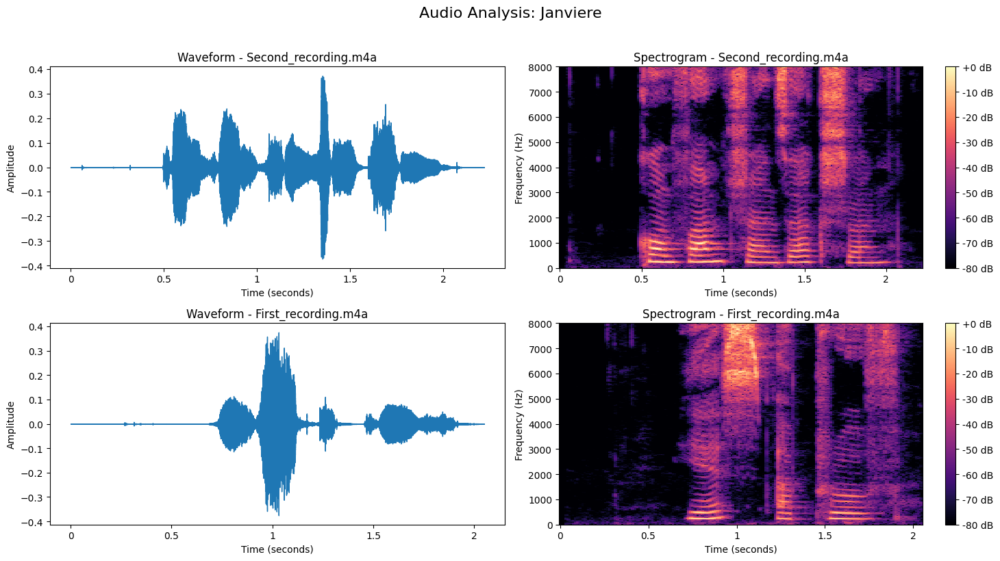

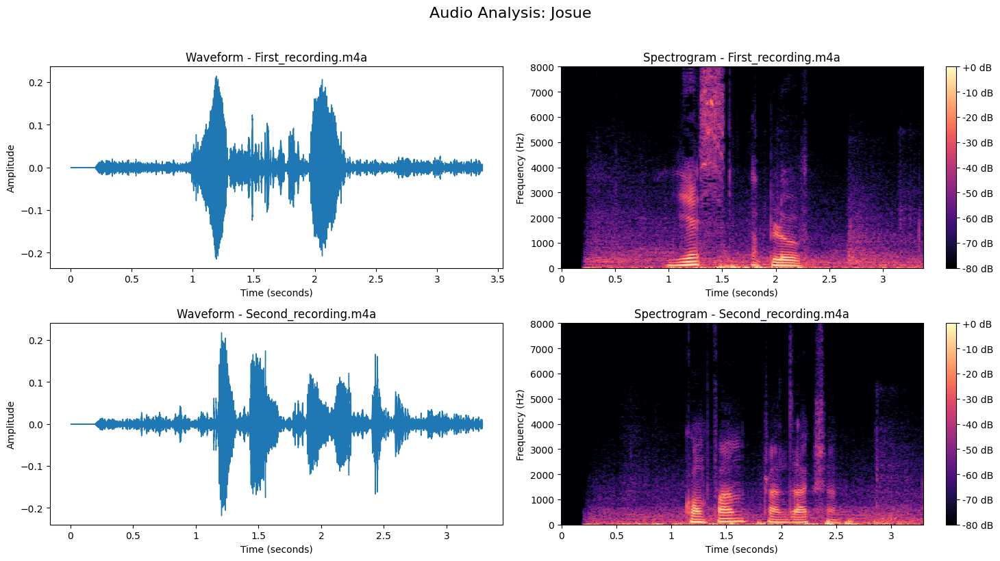

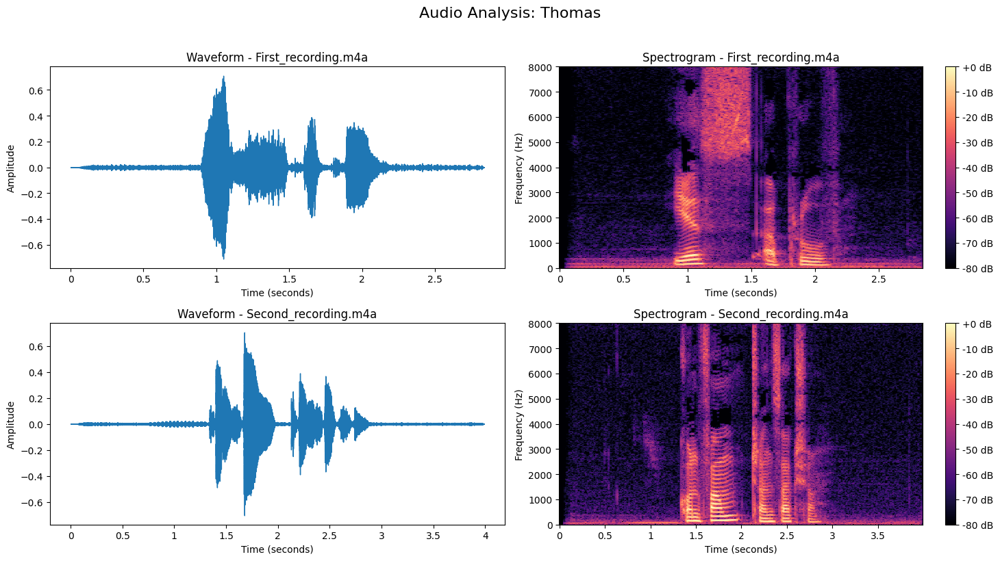

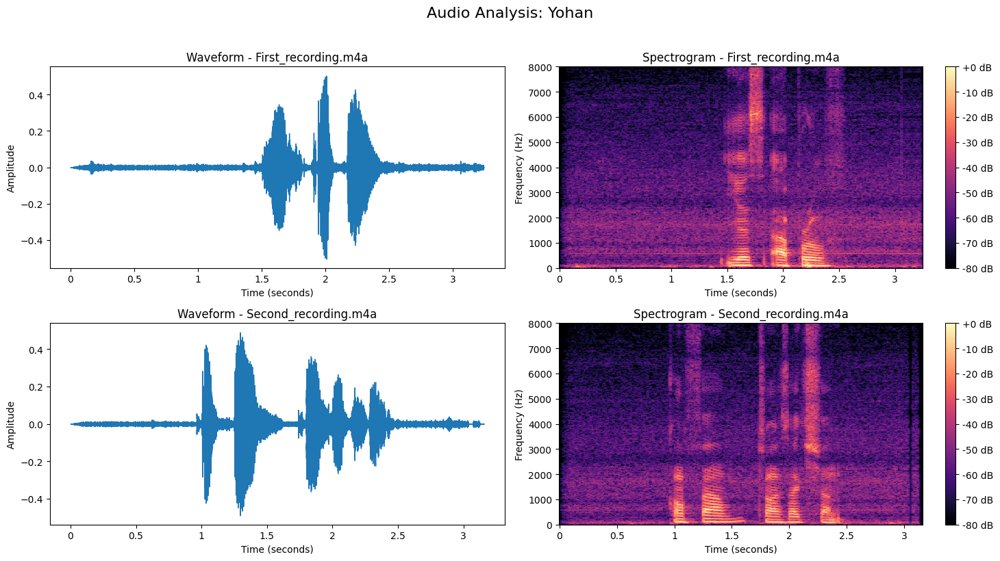

In [ ]:

# Generate waveform and spectrogram visualizations for each speaker

for speaker in sorted(set(record['speaker'] for record in audio_records)):

    speaker_records = [
        record for record in audio_records
        if record['speaker'] == speaker
    ]

    fig, axes = plt.subplots(
        len(speaker_records), 2,
        figsize=(15, 4 * len(speaker_records))
    )

    # Ensure axes are consistently arranged
    if len(speaker_records) == 1:
        axes = np.array([axes])

    for i, record in enumerate(speaker_records):

        audio = record['audio']
        sr = record['sample_rate']
        filename = record['filename']

        # Waveform
        librosa.display.waveshow(
            audio,
            sr=sr,
            ax=axes[i, 0]
        )

        axes[i, 0].set_title(f"Waveform - {filename}")
        axes[i, 0].set_xlabel("Time (seconds)")
        axes[i, 0].set_ylabel("Amplitude")

        # Spectrogram
        stft = np.abs(librosa.stft(audio))
        spectrogram_db = librosa.amplitude_to_db(
            stft,
            ref=np.max
        )

        img = librosa.display.specshow(
            spectrogram_db,
            sr=sr,
            x_axis='time',
            y_axis='hz',
            ax=axes[i, 1]
        )

        axes[i, 1].set_ylim(0, 8000)
        axes[i, 1].set_title(f"Spectrogram - {filename}")
        axes[i, 1].set_xlabel("Time (seconds)")
        axes[i, 1].set_ylabel("Frequency (Hz)")

        fig.colorbar(
            img,
            ax=axes[i, 1],
            format='%+2.0f dB'
        )

    fig.suptitle(
        f"Audio Analysis: {speaker}",
        fontsize=16,
        y=1.02
    )

    plt.tight_layout()
    plt.show()


### 3.1 Interpretation of Audio Waveforms and Spectrograms

The waveform and spectrogram visualizations revealed differences in the acoustic characteristics of the eight recordings collected from four speakers: Janviere, Josue, Thomas, and Yohan.

The recordings varied in duration, amplitude, speech activity and frequency distribution. Janviere's recordings were relatively short, lasting approximately 2.0–2.2 seconds, while Josue's and Yohan's recordings lasted approximately 3.2–3.4 seconds. Thomas's recordings showed a larger difference in duration, ranging from approximately 2.8 to 4.0 seconds.

The waveform visualizations showed variations in signal amplitude. Thomas's recordings exhibited relatively high peak amplitudes, whereas Josue's recordings had lower amplitudes. These differences indicate variations in recording loudness and support the need for consistent audio preprocessing.

The spectrograms revealed differences in the distribution of frequency energy across recordings. The horizontal harmonic structures provided information about the pitch characteristics of voiced speech, while higher-frequency energy represented additional speech components. Some recordings also showed possible low-level background noise.

Overall, the visual analysis demonstrated that the recordings contained distinguishable acoustic patterns but also exhibited differences in loudness, duration and recording conditions. These observations informed the subsequent audio preprocessing, augmentation and feature extraction stages.

## 4. Audio Augmentation

Audio augmentation is used to increase the diversity of the training data by creating modified versions of existing recordings. This helps the voice recognition model learn speaker characteristics under slightly different acoustic conditions.

Three augmentation techniques are applied:

- **Pitch shifting:** Changes the pitch by one semitone.
- **Time stretching:** Slows the recording slightly while preserving its pitch.
- **Background noise addition:** Adds low-level Gaussian noise at a controlled signal-to-noise ratio.

Each original recording produces three augmented versions. The original recordings are preserved for comparison and evaluation.

In [ ]:

# Define output directories
OUTPUT_PATH = os.path.join(OUTPUT_ROOT, 'Audio_Outputs')

AUGMENTED_PATH = os.path.join(OUTPUT_PATH, 'augmented_audio')
PITCH_PATH = os.path.join(AUGMENTED_PATH, 'pitch_shift')
STRETCH_PATH = os.path.join(AUGMENTED_PATH, 'time_stretch')
NOISE_PATH = os.path.join(AUGMENTED_PATH, 'background_noise')

# Create folders
for folder in [OUTPUT_PATH, AUGMENTED_PATH,
               PITCH_PATH, STRETCH_PATH, NOISE_PATH]:
    os.makedirs(folder, exist_ok=True)

print("Audio output folders created successfully.")
print("Output location:", OUTPUT_PATH)


Audio output folders created successfully.
Output location: /content/drive/MyDrive/ML- pipeline_Formative-2/outputs/Audio_Outputs


In [ ]:

# Store information about all augmented recordings
augmented_records = []

# Controlled settings
PITCH_STEPS = 1       # Increase pitch by one semitone
TIME_STRETCH_RATE = 0.95
NOISE_SNR_DB = 25     # Higher SNR means quieter added noise

rng = np.random.default_rng(42)

for index, record in enumerate(audio_records):

    audio = record['audio']
    sr = record['sample_rate']
    speaker = record['speaker']

    # Create a safe filename
    original_name = os.path.splitext(record['filename'])[0]
    safe_name = original_name.replace(' ', '_')

    # 1. Pitch shifting
    pitch_audio = librosa.effects.pitch_shift(
        y=audio,
        sr=sr,
        n_steps=PITCH_STEPS
    )

    # 2. Time stretching
    stretch_audio = librosa.effects.time_stretch(
        y=audio,
        rate=TIME_STRETCH_RATE
    )

    # 3. Background noise addition (25 dB SNR)
    signal_rms = np.sqrt(np.mean(audio ** 2))

    noise_rms = signal_rms / (10 ** (NOISE_SNR_DB / 20))

    noise = rng.normal(
        0,
        noise_rms,
        size=len(audio)
    )

    noise_audio = audio + noise

    # Prepare augmented versions
    augmentations = [
        ('pitch_shift', pitch_audio, PITCH_PATH),
        ('time_stretch', stretch_audio, STRETCH_PATH),
        ('background_noise', noise_audio, NOISE_PATH)
    ]

    for augmentation_name, augmented_audio, folder in augmentations:

        # Create a speaker-specific folder
        speaker_folder = os.path.join(folder, speaker)
        os.makedirs(speaker_folder, exist_ok=True)

        output_filename = (
            f"{speaker}_{safe_name}_{augmentation_name}.wav"
        )

        output_file = os.path.join(
            speaker_folder,
            output_filename
        )

        # Prevent values outside the normal audio amplitude range
        peak = np.max(np.abs(augmented_audio))

        if peak > 0.99:
            augmented_audio = augmented_audio * (0.99 / peak)

        # Save augmented audio without changing the original
        sf.write(
            output_file,
            augmented_audio,
            sr,
            subtype='PCM_16'
        )

        # Keep metadata and audio in memory for later processing
        augmented_records.append({
            'speaker': speaker,
            'filename': output_filename,
            'original_filename': record['filename'],
            'file_path': output_file,
            'sample_rate': sr,
            'duration_seconds': librosa.get_duration(
                y=augmented_audio,
                sr=sr
            ),
            'augmentation': augmentation_name,
            'audio': augmented_audio
        })

print("Audio augmentation completed!")
print("Original recordings:", len(audio_records))
print("Augmented recordings:", len(augmented_records))
print("Total recordings:", len(audio_records) + len(augmented_records))


Audio augmentation completed!
Original recordings: 8
Augmented recordings: 24
Total recordings: 32


In [ ]:

# Summarize the augmented recordings
augmentation_summary = pd.DataFrame(augmented_records)

print("Augmentation counts:")
print(augmentation_summary['augmentation'].value_counts())

print("\nAugmented recordings per speaker:")
print(
    augmentation_summary.groupby(
        ['speaker', 'augmentation']
    ).size().unstack(fill_value=0)
)

print("\nSample augmented files:")
display(
    augmentation_summary[
        ['speaker', 'original_filename', 'augmentation',
         'duration_seconds', 'sample_rate']
    ].head(10)
)


Augmentation counts:
augmentation
pitch_shift         8
time_stretch        8
background_noise    8
Name: count, dtype: int64

Augmented recordings per speaker:
augmentation  background_noise  pitch_shift  time_stretch
speaker                                                  
Janviere                     2            2             2
Josue                        2            2             2
Thomas                       2            2             2
Yohan                        2            2             2

Sample augmented files:


,speaker,original_filename,augmentation,duration_seconds,sample_rate
0,Josue,First_recording.m4a,pitch_shift,3.370667,48000
1,Josue,First_recording.m4a,time_stretch,3.548062,48000
2,Josue,First_recording.m4a,background_noise,3.370667,48000
3,Josue,Second_recording.m4a,pitch_shift,3.285333,48000
4,Josue,Second_recording.m4a,time_stretch,3.458250,48000
5,Josue,Second_recording.m4a,background_noise,3.285333,48000
6,Janviere,Second_recording.m4a,pitch_shift,2.218667,48000
7,Janviere,Second_recording.m4a,time_stretch,2.335437,48000
8,Janviere,Second_recording.m4a,background_noise,2.218667,48000
9,Janviere,First_recording.m4a,pitch_shift,2.048000,48000


### 4.1 Audio Augmentation Results

Three augmentation techniques were applied to the eight original audio recordings: pitch shifting, time stretching and background noise addition.

Pitch shifting increased the pitch of each recording by one semitone while maintaining approximately the original duration. Time stretching used a rate of 0.95, increasing the duration of each recording while preserving its pitch. Background noise was added at a signal-to-noise ratio of 25 dB to simulate variations in recording environments.

Each technique was applied to all eight original recordings, producing 24 augmented audio samples. Consequently, the dataset contained 32 audio files, comprising eight original recordings and 24 augmented versions.

The augmentation results were evenly distributed across the four speakers, with each speaker contributing two recordings to each augmentation category.

This process increased the diversity of the audio samples and provided additional examples for subsequent feature extraction and voiceprint modelling. The original recordings were preserved separately from their augmented versions.

### 4.2 Visual Comparison of Original and Augmented Audio

A visual comparison is performed between selected original recordings and their augmented versions. Waveforms and spectrograms are used to observe changes caused by pitch shifting, time stretching and background noise addition.

#### Original Voice

In [60]:
from IPython.display import Audio, display

for record in audio_records:
    print(f"Speaker: {record['speaker']}")
    print(f"File: {record['filename']}")
    display(Audio(
        record['audio'],
        rate=record['sample_rate']
    ))

Speaker: Josue
File: First_recording.m4a


Speaker: Josue
File: Second_recording.m4a


Speaker: Janviere
File: Second_recording.m4a


Speaker: Janviere
File: First_recording.m4a


Speaker: Yohan
File: First_recording.m4a


Speaker: Yohan
File: Second_recording.m4a


Speaker: Thomas
File: First_recording.m4a


Speaker: Thomas
File: Second_recording.m4a


#### Augumented Voice


In [62]:
for record in augmented_records:
    if record['speaker'] == 'Thomas':
        print(record['filename'])
        print("Augmentation:", record['augmentation'])

        display(Audio(
            record['audio'],
            rate=record['sample_rate']
        ))

Thomas_First_recording_pitch_shift.wav
Augmentation: pitch_shift


Thomas_First_recording_time_stretch.wav
Augmentation: time_stretch


Thomas_First_recording_background_noise.wav
Augmentation: background_noise


Thomas_Second_recording_pitch_shift.wav
Augmentation: pitch_shift


Thomas_Second_recording_time_stretch.wav
Augmentation: time_stretch


Thomas_Second_recording_background_noise.wav
Augmentation: background_noise


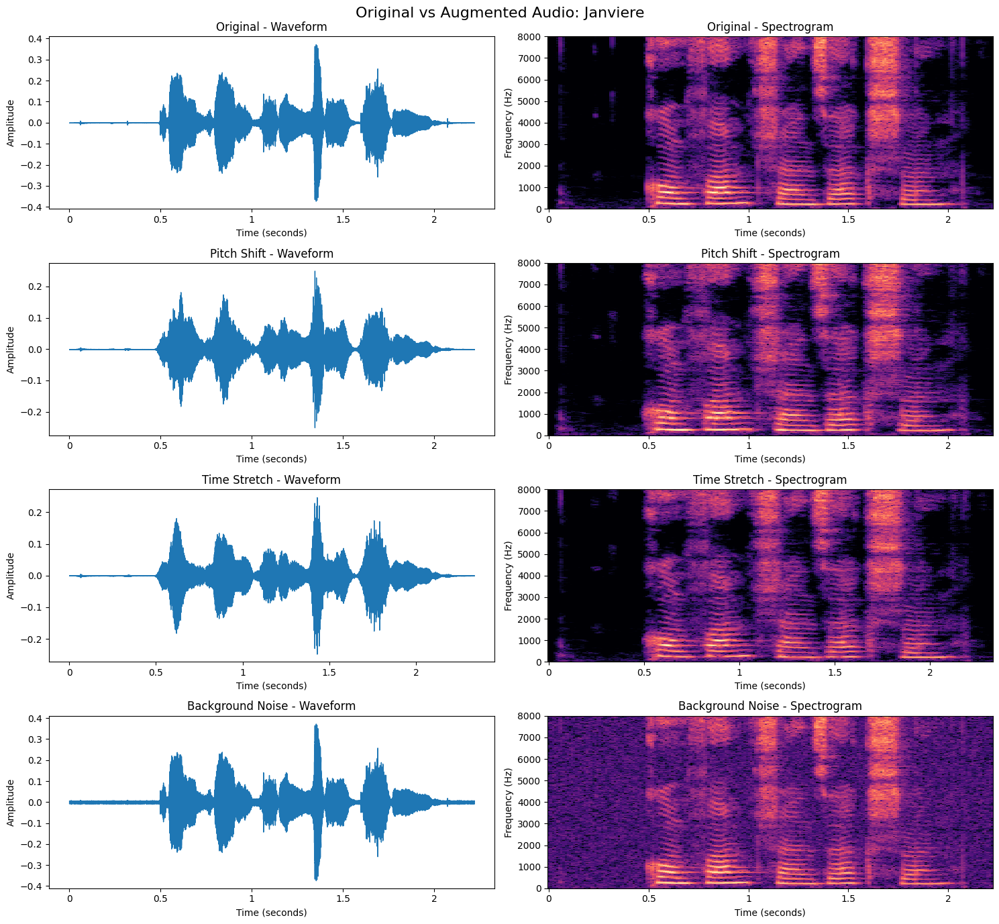

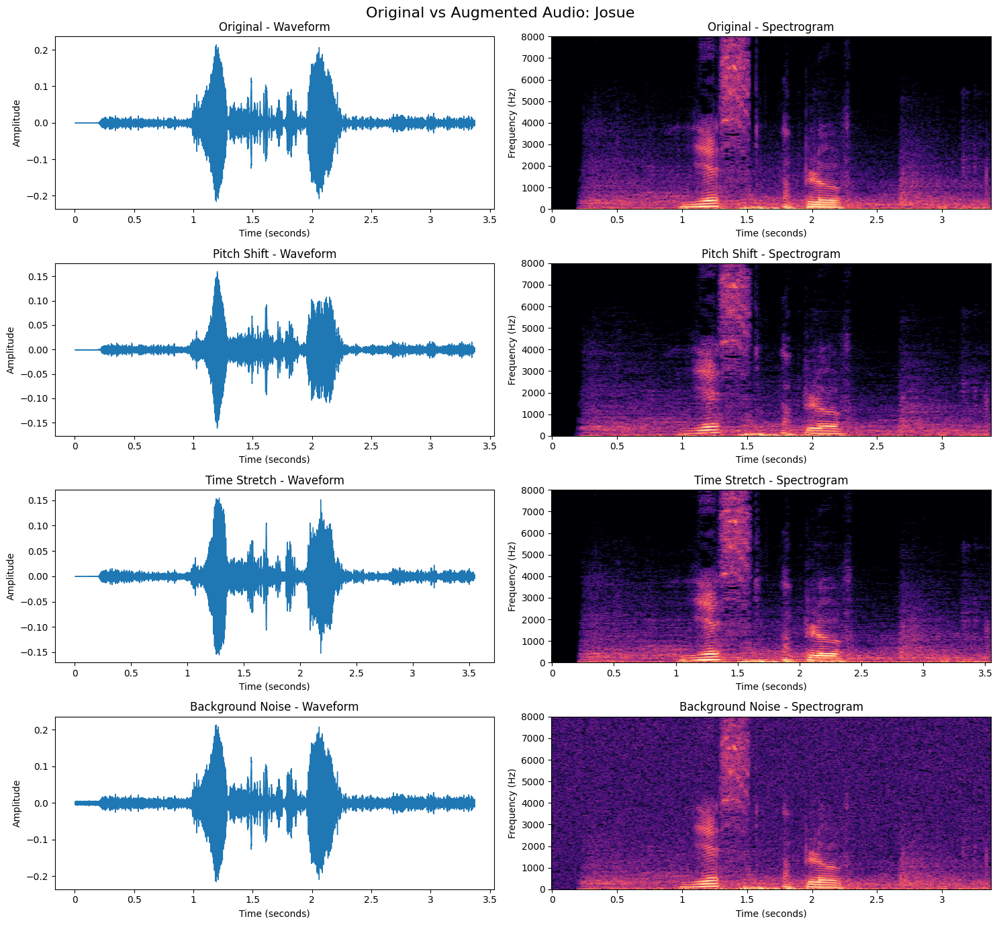

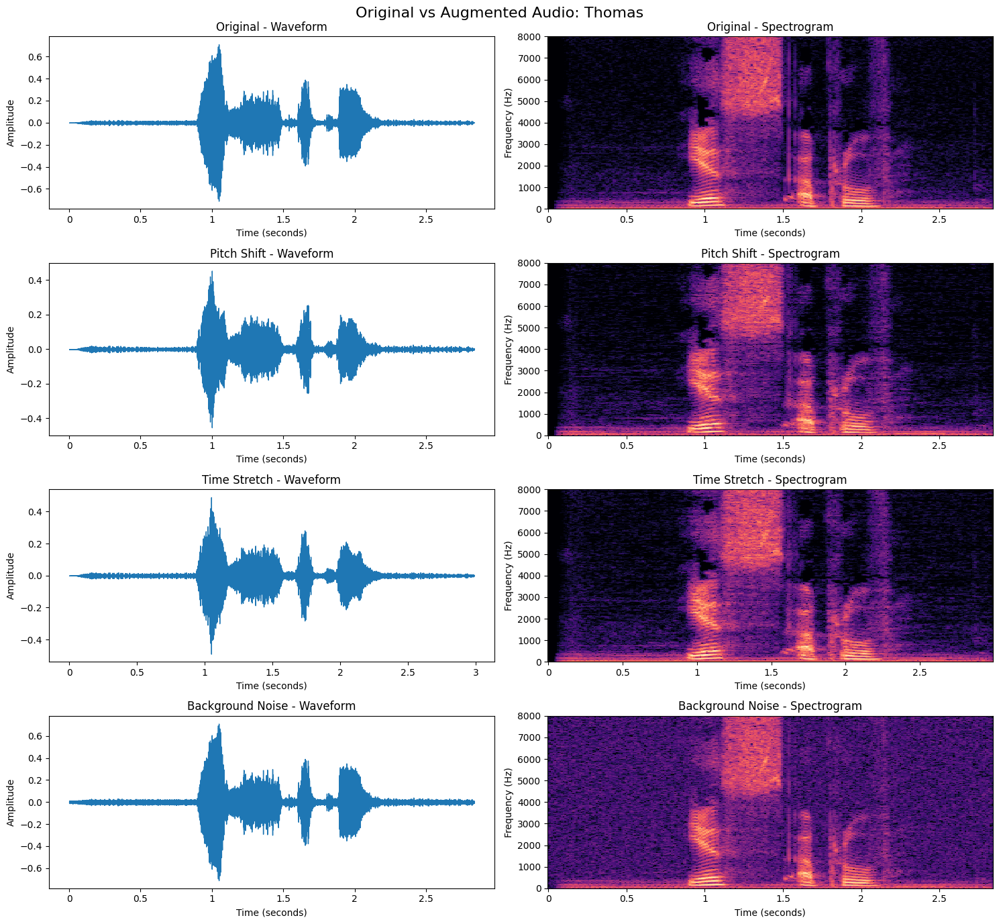

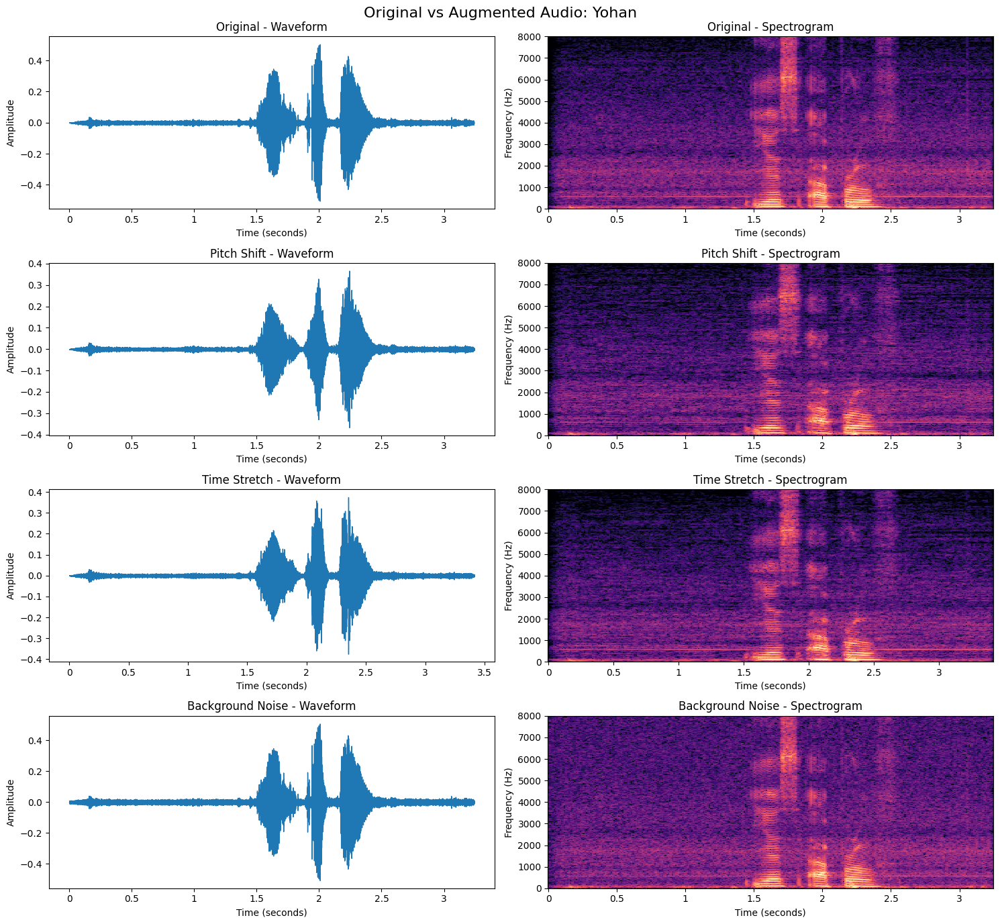

In [ ]:

# Compare original and augmented recordings for each speaker

for speaker in sorted(set(r['speaker'] for r in audio_records)):

    # Select one original recording for this speaker
    original = next(
        r for r in audio_records
        if r['speaker'] == speaker
    )

    # Find its three augmented versions
    variants = [
        r for r in augmented_records
        if r['speaker'] == speaker
        and r['original_filename'] == original['filename']
    ]

    comparisons = [
        ('Original', original['audio']),
        ('Pitch Shift', next(
            r['audio'] for r in variants
            if r['augmentation'] == 'pitch_shift'
        )),
        ('Time Stretch', next(
            r['audio'] for r in variants
            if r['augmentation'] == 'time_stretch'
        )),
        ('Background Noise', next(
            r['audio'] for r in variants
            if r['augmentation'] == 'background_noise'
        ))
    ]

    fig, axes = plt.subplots(4, 2, figsize=(15, 14))

    for i, (label, audio) in enumerate(comparisons):

        # Waveform
        librosa.display.waveshow(
            audio,
            sr=original['sample_rate'],
            ax=axes[i, 0]
        )
        axes[i, 0].set_title(f'{label} - Waveform')
        axes[i, 0].set_xlabel('Time (seconds)')
        axes[i, 0].set_ylabel('Amplitude')

        # Spectrogram
        D = np.abs(librosa.stft(audio))
        S_db = librosa.amplitude_to_db(D, ref=np.max)

        img = librosa.display.specshow(
            S_db,
            sr=original['sample_rate'],
            x_axis='time',
            y_axis='hz',
            ax=axes[i, 1]
        )

        axes[i, 1].set_ylim(0, 8000)
        axes[i, 1].set_title(f'{label} - Spectrogram')
        axes[i, 1].set_xlabel('Time (seconds)')
        axes[i, 1].set_ylabel('Frequency (Hz)')

    fig.suptitle(
        f'Original vs Augmented Audio: {speaker}',
        fontsize=16
    )

    plt.tight_layout()
    plt.show()


## 5. Audio Feature Extraction

Audio feature extraction converts speech recordings into numerical representations that can be used by machine learning algorithms.

The following features are extracted from both original and augmented recordings:

- **MFCCs:** Represent the spectral characteristics of speech and are useful for speaker recognition.
- **Spectral roll-off:** Describes the distribution of frequency energy in the audio signal.
- **RMS energy:** Measures the signal's average energy.
- **Spectral centroid:** Represents the centre of mass of the frequency spectrum.
- **Spectral bandwidth:** Measures the spread of frequencies around the spectral centroid.
- **Zero-crossing rate:** Measures how frequently the audio signal changes sign.

For each feature, statistical summaries (mean and standard deviation) are calculated across the audio frames. The resulting feature dataset is saved as `audio_features.csv` for subsequent analysis and voiceprint modelling.

In [ ]:

# Combine original and augmented recordings

all_audio_records = []

# Add original recordings
for record in audio_records:
    all_audio_records.append({
        'speaker': record['speaker'],
        'filename': record['filename'],
        'original_filename': record['filename'],
        'file_path': record['file_path'],
        'sample_rate': record['sample_rate'],
        'duration_seconds': record['duration_seconds'],
        'augmentation': 'original',
        'audio': record['audio']
    })

# Add augmented recordings
all_audio_records.extend(augmented_records)

print("Total recordings for feature extraction:",
      len(all_audio_records))


Total recordings for feature extraction: 32


In [ ]:

# Function to extract numerical features from one recording

def extract_audio_features(record):

    audio = record['audio']
    sr = record['sample_rate']

    features = {
        'speaker': record['speaker'],
        'filename': record['filename'],
        'original_filename': record['original_filename'],
        'augmentation': record['augmentation'],
        'sample_rate': sr,
        'duration_seconds': record['duration_seconds']
    }

    # 1. MFCC features (13 coefficients)
    mfcc = librosa.feature.mfcc(
        y=audio,
        sr=sr,
        n_mfcc=13
    )

    for i in range(13):
        features[f'mfcc_{i+1}_mean'] = np.mean(mfcc[i])
        features[f'mfcc_{i+1}_std'] = np.std(mfcc[i])

    # 2. Spectral roll-off
    rolloff = librosa.feature.spectral_rolloff(
        y=audio,
        sr=sr,
        roll_percent=0.85
    )

    features['rolloff_mean'] = np.mean(rolloff)
    features['rolloff_std'] = np.std(rolloff)

    # 3. RMS energy
    rms = librosa.feature.rms(y=audio)

    features['rms_energy_mean'] = np.mean(rms)
    features['rms_energy_std'] = np.std(rms)

    # 4. Spectral centroid
    centroid = librosa.feature.spectral_centroid(
        y=audio,
        sr=sr
    )

    features['spectral_centroid_mean'] = np.mean(centroid)
    features['spectral_centroid_std'] = np.std(centroid)

    # 5. Spectral bandwidth
    bandwidth = librosa.feature.spectral_bandwidth(
        y=audio,
        sr=sr
    )

    features['spectral_bandwidth_mean'] = np.mean(bandwidth)
    features['spectral_bandwidth_std'] = np.std(bandwidth)

    # 6. Zero-crossing rate
    zcr = librosa.feature.zero_crossing_rate(y=audio)

    features['zero_crossing_rate_mean'] = np.mean(zcr)
    features['zero_crossing_rate_std'] = np.std(zcr)

    return features


# Extract features from every recording
feature_rows = []

for record in all_audio_records:
    feature_rows.append(
        extract_audio_features(record)
    )

# Create the final feature DataFrame
audio_features_df = pd.DataFrame(feature_rows)

print("Feature extraction completed!")
print("Dataset shape:", audio_features_df.shape)
print("Number of extracted features:",
      audio_features_df.shape[1] - 6)


Feature extraction completed!
Dataset shape: (32, 42)
Number of extracted features: 36


In [ ]:

import os

OUTPUT_PATH = os.path.join(OUTPUT_ROOT, 'Audio_Outputs')

# Recreate the directory if it does not exist
os.makedirs(OUTPUT_PATH, exist_ok=True)

print("Directory exists:", os.path.isdir(OUTPUT_PATH))
print("Output path:", OUTPUT_PATH)


Directory exists: True
Output path: /content/drive/MyDrive/ML- pipeline_Formative-2/outputs/Audio_Outputs


In [ ]:

# Save extracted features to Google Drive

FEATURES_PATH = os.path.join(
    OUTPUT_PATH,
    'audio_features.csv'
)

audio_features_df.to_csv(
    FEATURES_PATH,
    index=False
)

print("Feature dataset saved successfully!")
print("File location:", FEATURES_PATH)
print("Dataset shape:", audio_features_df.shape)

# Display a preview
display(audio_features_df.head())


Feature dataset saved successfully!
File location: /content/drive/MyDrive/ML- pipeline_Formative-2/outputs/Audio_Outputs/audio_features.csv
Dataset shape: (32, 42)


,speaker,filename,original_filename,augmentation,sample_rate,duration_seconds,mfcc_1_mean,mfcc_1_std,mfcc_2_mean,mfcc_2_std,...,rolloff_mean,rolloff_std,rms_energy_mean,rms_energy_std,spectral_centroid_mean,spectral_centroid_std,spectral_bandwidth_mean,spectral_bandwidth_std,zero_crossing_rate_mean,zero_crossing_rate_std
0,Josue,First_recording.m4a,First_recording.m4a,original,48000,3.370667,-497.133911,76.808342,163.223343,53.941391,...,1823.910686,2632.806641,0.019175,0.023026,1077.778865,1468.108086,1846.584534,923.506468,0.019527,0.040951
1,Josue,Second_recording.m4a,Second_recording.m4a,original,48000,3.285333,-508.239746,70.915108,163.966248,57.776688,...,1187.803398,2196.235840,0.020242,0.019691,734.931431,1073.499485,1643.270574,923.692578,0.009252,0.012423
2,Janviere,Second_recording.m4a,Second_recording.m4a,original,48000,2.218667,-437.837616,143.326141,63.063793,65.182724,...,9940.639952,3472.954355,0.029293,0.030048,5059.628968,2368.995751,4410.998076,1212.297218,0.122696,0.108234
3,Janviere,First_recording.m4a,First_recording.m4a,original,48000,2.048000,-521.377930,154.770447,36.826309,68.243568,...,12147.546956,2781.225979,0.018068,0.029464,6483.323195,1908.314141,4950.872237,1311.838214,0.172879,0.111724
4,Yohan,First_recording.m4a,First_recording.m4a,original,48000,3.242667,-374.427856,63.257935,144.952225,40.043739,...,4818.596311,1779.919686,0.027349,0.044391,2656.376617,1017.269348,3131.576683,629.837588,0.058467,0.039369


In [ ]:

FEATURES_PATH = os.path.join(OUTPUT_PATH, 'audio_features.csv')

audio_features_df.to_csv(FEATURES_PATH, index=False)

print("Feature dataset saved successfully!")
print("File location:", FEATURES_PATH)
print("Dataset shape:", audio_features_df.shape)

print("\nFile exists:", os.path.exists(FEATURES_PATH))


Feature dataset saved successfully!
File location: /content/drive/MyDrive/ML- pipeline_Formative-2/outputs/Audio_Outputs/audio_features.csv
Dataset shape: (32, 42)

File exists: True


In [ ]:
print("Available columns:")
print(audio_features_df.columns.tolist())

print("\nRecording types:")
print(audio_features_df['augmentation'].value_counts())

print("\nOriginal recordings per speaker:")
print(
    audio_features_df[
        audio_features_df['augmentation'] == 'original'
    ].groupby('speaker')['original_filename'].nunique()
)

print("\nSample recording identification:")
display(
    audio_features_df[
        ['speaker', 'original_filename', 'augmentation']
    ].head(12)
)

Available columns:
['speaker', 'filename', 'original_filename', 'augmentation', 'sample_rate', 'duration_seconds', 'mfcc_1_mean', 'mfcc_1_std', 'mfcc_2_mean', 'mfcc_2_std', 'mfcc_3_mean', 'mfcc_3_std', 'mfcc_4_mean', 'mfcc_4_std', 'mfcc_5_mean', 'mfcc_5_std', 'mfcc_6_mean', 'mfcc_6_std', 'mfcc_7_mean', 'mfcc_7_std', 'mfcc_8_mean', 'mfcc_8_std', 'mfcc_9_mean', 'mfcc_9_std', 'mfcc_10_mean', 'mfcc_10_std', 'mfcc_11_mean', 'mfcc_11_std', 'mfcc_12_mean', 'mfcc_12_std', 'mfcc_13_mean', 'mfcc_13_std', 'rolloff_mean', 'rolloff_std', 'rms_energy_mean', 'rms_energy_std', 'spectral_centroid_mean', 'spectral_centroid_std', 'spectral_bandwidth_mean', 'spectral_bandwidth_std', 'zero_crossing_rate_mean', 'zero_crossing_rate_std']

Recording types:
augmentation
original            8
pitch_shift         8
time_stretch        8
background_noise    8
Name: count, dtype: int64

Original recordings per speaker:
speaker
Janviere    2
Josue       2
Thomas      2
Yohan       2
Name: original_filename, dtype: 

,speaker,original_filename,augmentation
0,Josue,First_recording.m4a,original
1,Josue,Second_recording.m4a,original
2,Janviere,Second_recording.m4a,original
3,Janviere,First_recording.m4a,original
4,Yohan,First_recording.m4a,original
5,Yohan,Second_recording.m4a,original
6,Thomas,First_recording.m4a,original
7,Thomas,Second_recording.m4a,original
8,Josue,First_recording.m4a,pitch_shift
9,Josue,First_recording.m4a,time_stretch


## 6. Voiceprint Verification Model

### 6.1 Objective

The objective of this stage was to develop a machine learning model capable of identifying speakers based on acoustic characteristics extracted from their audio recordings. Voiceprint verification uses distinctive speech-related features to determine whether an audio sample is consistent with a particular speaker.

The extracted audio features from the previous stage were used as input to the model. These included Mel-Frequency Cepstral Coefficients (MFCCs), spectral roll-off, RMS energy, spectral centroid, spectral bandwidth, and zero-crossing rate.

The dataset contained four speakers: Josue, Janviere, Yohan, and Thomas. Each speaker contributed two original recordings, resulting in eight original recordings. Three augmentation techniques—pitch shifting, time stretching, and background noise addition—were applied to each original recording, producing 24 additional samples. Therefore, the final feature dataset contained 32 samples.

### 6.2 Dataset Preparation and Splitting

Before training the model, the extracted feature dataset was divided into training and testing sets. A group-based splitting strategy was adopted to prevent data leakage.

Since each original recording had three augmented versions, all four versions of a recording were kept within the same partition. This prevented augmented versions of a recording from appearing in both training and testing data.

One original recording from each speaker was reserved for testing, while the other original recording and its three augmented versions were used for training.

The resulting dataset was expected to contain:

- **Training set:** 16 samples, consisting of four samples per speaker.
- **Testing set:** 4 original recordings, consisting of one sample per speaker.
- **Input features:** 36 acoustic features extracted from the audio recordings.
- **Target variable:** Speaker identity, representing one of the four participants.

This approach allowed the model to be evaluated on original recordings that were not used during training.

### 6.3 Model Development

A supervised classification approach was selected for voiceprint modelling. The model uses the extracted acoustic features to learn patterns associated with each speaker and predict the identity of an unseen recording.

Feature scaling is important because the extracted features have different numerical ranges. Standardisation was therefore considered before model training to ensure that features with larger numerical values did not dominate the learning process.

The model was designed as a proof of concept for speaker identification and basic claimed-identity matching. It was not intended to function as a production-ready biometric authentication system.

### 6.4 Model Evaluation

The model was evaluated using the following performance metrics:

- **Accuracy:** Measures the proportion of correctly identified speakers.
- **Precision:** Measures how many predictions for a speaker were correct.
- **Recall:** Measures how many recordings belonging to a speaker were correctly identified.
- **F1-score:** Provides a balance between precision and recall.
- **Log loss:** Evaluates the quality of the predicted class probabilities, where lower values indicate better probability predictions.

A confusion matrix was also used to examine correct and incorrect speaker classifications.

A matching and non-matching simulation was planned to demonstrate whether a recording's predicted speaker identity agreed with a claimed identity.

### 6.5 Limitations

The voiceprint experiment was conducted using a very small dataset containing only two original recordings per speaker. Although augmentation increased the number of training samples, augmented recordings are transformations of existing recordings rather than independent voice samples.

Furthermore, the testing set contained only four original recordings. Consequently, the evaluation metrics should be interpreted as preliminary experimental results rather than reliable estimates of performance on unseen speakers or real-world authentication scenarios.

A larger dataset containing more independent recordings from each speaker, recorded under different conditions, would be necessary to develop and evaluate a more reliable voice verification system.

### 6.1 Dataset Preparation and Train-Test Splitting

The extracted audio feature dataset was prepared for supervised speaker classification. The `speaker` column was selected as the target variable, while the 36 extracted acoustic features were used as model inputs.

To prevent data leakage, a recording-group strategy was applied. Each original recording and its three augmented versions were assigned to the same group. One original recording per speaker was reserved for testing, while the remaining original recording and its augmented versions were used for training.

Only original recordings were included in the test set to evaluate the model on audio samples that had not been used to generate the training data.

In [ ]:
# Create a working copy of the extracted features
voice_df = audio_features_df.copy()

# Group each original recording with all its augmented versions
voice_df['recording_group'] = (
    voice_df['speaker'].astype(str) + "_" +
    voice_df['original_filename'].astype(str)
)

# Identify original recordings
originals = voice_df[
    voice_df['augmentation'] == 'original'
].copy()

# Select one original recording per speaker for testing
test_recordings = (
    originals.groupby('speaker')['original_filename']
    .apply(lambda x: sorted(x.unique())[-1])
    .to_dict()
)

print("Held-out original recordings:")
for speaker, filename in test_recordings.items():
    print(f"{speaker}: {filename}")

# Identify the groups reserved for testing
test_group_ids = {
    f"{speaker}_{filename}"
    for speaker, filename in test_recordings.items()
}

# Create training set: remaining original recordings and their augmentations
train_df = voice_df[
    ~voice_df['recording_group'].isin(test_group_ids)
].copy()

# Create testing set: only the held-out original recordings
test_df = originals[
    originals.apply(
        lambda row: row['original_filename'] == test_recordings[row['speaker']],
        axis=1
    )
].copy()

# Identify the 36 acoustic feature columns
feature_prefixes = (
    'mfcc_', 'rolloff_', 'rms_energy_',
    'spectral_centroid_', 'spectral_bandwidth_',
    'zero_crossing_rate_'
)

feature_columns = [
    col for col in voice_df.columns
    if col.startswith(feature_prefixes)
]

# Separate features (X) and target labels (y)
X_train = train_df[feature_columns]
y_train = train_df['speaker']

X_test = test_df[feature_columns]
y_test = test_df['speaker']

# Display dataset information
print("\nTraining shape:", X_train.shape)
print("Testing shape:", X_test.shape)
print("Number of acoustic features:", len(feature_columns))

print("\nTraining recordings per speaker:")
print(y_train.value_counts())

print("\nTesting recordings per speaker:")
print(y_test.value_counts())

Held-out original recordings:
Janviere: Second_recording.m4a
Josue: Second_recording.m4a
Thomas: Second_recording.m4a
Yohan: Second_recording.m4a

Training shape: (16, 36)
Testing shape: (4, 36)
Number of acoustic features: 36

Training recordings per speaker:
speaker
Josue       4
Janviere    4
Yohan       4
Thomas      4
Name: count, dtype: int64

Testing recordings per speaker:
speaker
Josue       1
Janviere    1
Yohan       1
Thomas      1
Name: count, dtype: int64


### 6.2 Data Leakage Verification

A data leakage check was conducted to ensure that no original recording or its augmented versions appeared in both the training and testing sets. This is important because augmented samples originate from the same audio recording and could otherwise make the model evaluation overly optimistic.

The testing set was also checked to confirm that it contained only original recordings.

In [52]:
# Check for overlapping recording groups
train_groups = set(train_df['recording_group'])
test_groups = set(test_df['recording_group'])

overlap = train_groups.intersection(test_groups)

print("Overlapping recording groups:", overlap)
print("No data leakage:", len(overlap) == 0)

# Confirm that test samples are original recordings
print(
    "Test contains only original recordings:",
    (test_df['augmentation'] == 'original').all()
)

Overlapping recording groups: set()
No data leakage: True
Test contains only original recordings: True


### 6.3 Voiceprint Model Training

A Logistic Regression classifier was selected as the initial voiceprint identification model. The classifier learns patterns in the extracted acoustic features and uses these patterns to predict the identity of a speaker.

StandardScaler was incorporated into a machine learning pipeline to standardise the numerical features before classification. This is particularly important because acoustic features such as MFCCs, spectral roll-off, and RMS energy have different numerical scales.

The model was trained using 16 samples from four speakers. A separate validation set was not created because the dataset contained only two independent original recordings per speaker. Instead, one original recording per speaker and its augmented versions were used for training, while the other original recording was reserved for final testing.

In [53]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    log_loss,
    classification_report,
    confusion_matrix
)

import pandas as pd
import numpy as np

# Create the voiceprint classification pipeline
voiceprint_model = Pipeline([
    ('scaler', StandardScaler()),
    ('classifier', LogisticRegression(
        max_iter=2000,
        class_weight='balanced',
        random_state=42
    ))
])

# Train the model
voiceprint_model.fit(X_train, y_train)

print("Voiceprint model trained successfully.")
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Number of features:", len(feature_columns))

Voiceprint model trained successfully.
Training samples: 16
Testing samples: 4
Number of features: 36


### 6.4 Evaluation of the Voiceprint Model

After training the Logistic Regression classifier, its performance was evaluated using the four held-out original audio recordings.

The evaluation focused on measuring how accurately the model could identify the four speakers based on their extracted acoustic features.

The following performance metrics were used:

- **Accuracy:** Measures the proportion of correctly classified recordings.
- **Precision:** Measures the proportion of correct speaker predictions among all predictions for each speaker.
- **Recall:** Measures the proportion of actual recordings correctly identified for each speaker.
- **F1-score:** Provides a balance between precision and recall.
- **Log Loss:** Evaluates the quality of the predicted class probabilities, with lower values indicating better probability estimates.

A classification report and confusion matrix were also generated to provide a more detailed view of the model's performance.

Since the testing dataset contains only four independent original recordings, the results are interpreted as preliminary findings rather than a reliable measure of real-world voice verification performance.

In [ ]:
# Generate predictions
y_pred = voiceprint_model.predict(X_test)

# Generate class probabilities
y_prob = voiceprint_model.predict_proba(X_test)

# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test, y_pred, average='macro', zero_division=0
)

recall = recall_score(
    y_test, y_pred, average='macro', zero_division=0
)

f1 = f1_score(
    y_test, y_pred, average='macro', zero_division=0
)

loss = log_loss(
    y_test, y_prob,
    labels=voiceprint_model.classes_
)

# Display metrics
print("VOICEPRINT MODEL EVALUATION")
print("---------------------------")
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")
print(f"Log loss:  {loss:.4f}")

# Classification report
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    labels=voiceprint_model.classes_,
    zero_division=0
))

# Confusion matrix
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=voiceprint_model.classes_
)

cm_df = pd.DataFrame(
    cm,
    index=voiceprint_model.classes_,
    columns=voiceprint_model.classes_
)

print("\nConfusion Matrix:")
display(cm_df)

### 6.5 Matching and Non-Matching Speaker Verification Simulation

A speaker verification simulation was implemented to demonstrate the basic matching and non-matching process.

For each held-out audio recording, the trained classifier predicts the speaker's identity. This prediction is then compared with the claimed identity.

- **Matching:** The predicted speaker identity agrees with the claimed identity.
- **Non-matching:** The predicted speaker identity differs from the claimed identity.

The simulation demonstrates how extracted voice features can support basic speaker identity checks. However, this is a simplified closed-set classification demonstration rather than a complete biometric verification system. It does not use a calibrated authentication threshold or establish whether a recording belongs to someone outside the four known speakers.

In [54]:
# Create a verification results table
verification_results = []

for index, row in test_df.iterrows():

    # Actual identity of the recording
    actual_speaker = row['speaker']

    # Model prediction for this recording
    predicted_speaker = voiceprint_model.predict(
        X_test.loc[[index]]
    )[0]

    # Matching simulation: claimed identity is the actual speaker
    matching_claim = actual_speaker

    matching_result = (
        predicted_speaker == matching_claim
    )

    # Non-matching simulation: choose a different claimed speaker
    other_speakers = [
        speaker for speaker in voiceprint_model.classes_
        if speaker != actual_speaker
    ]

    non_matching_claim = other_speakers[0]

    non_matching_result = (
        predicted_speaker == non_matching_claim
    )

    verification_results.append({
        'Actual Speaker': actual_speaker,
        'Predicted Speaker': predicted_speaker,
        'Matching Claim': matching_claim,
        'Matching Result': 'MATCH' if matching_result else 'NO MATCH',
        'Non-Matching Claim': non_matching_claim,
        'Non-Matching Result': 'MATCH' if non_matching_result else 'NO MATCH'
    })

# Display results
verification_df = pd.DataFrame(verification_results)

display(verification_df)

,Actual Speaker,Predicted Speaker,Matching Claim,Matching Result,Non-Matching Claim,Non-Matching Result
0,Josue,Josue,Josue,MATCH,Janviere,NO MATCH
1,Janviere,Janviere,Janviere,MATCH,Josue,NO MATCH
2,Yohan,Yohan,Yohan,MATCH,Janviere,NO MATCH
3,Thomas,Thomas,Thomas,MATCH,Janviere,NO MATCH


In [55]:
print("VOICEPRINT VERIFICATION SIMULATION")
print("----------------------------------")

matching_success = (
    verification_df['Matching Result'] == 'MATCH'
).sum()

non_matching_rejection = (
    verification_df['Non-Matching Result'] == 'NO MATCH'
).sum()

print(f"Matching claims accepted: {matching_success}/4")

print(
    f"Non-matching claims rejected: "
    f"{non_matching_rejection}/4"
)

VOICEPRINT VERIFICATION SIMULATION
----------------------------------
Matching claims accepted: 4/4
Non-matching claims rejected: 4/4


#### 6.5.1 Matching and Non-Matching Speaker Verification Results

The voiceprint verification simulation was conducted using four held-out original recordings representing Josue, Janviere, Yohan, and Thomas.

For each recording, the trained Logistic Regression classifier predicted the speaker's identity. The predicted identity was then compared with both the genuine speaker identity and an alternative claimed identity.

The results showed that all four recordings were correctly classified:

- Josue was correctly identified as Josue.
- Janviere was correctly identified as Janviere.
- Yohan was correctly identified as Yohan.
- Thomas was correctly identified as Thomas.

All four genuine identity claims were accepted, resulting in 4 out of 4 successful matches. Additionally, all four alternative identity claims were rejected, resulting in 4 out of 4 successful non-matching checks.

These results demonstrate that the extracted acoustic features enabled the trained classifier to distinguish the four speakers within this experimental dataset.

However, the results should be interpreted cautiously because the evaluation involved only four independent test recordings. The non-matching simulation also used alternative identities from the same four known speakers rather than recordings from completely unseen individuals. Therefore, the experiment demonstrates basic closed-set speaker identification and claimed-identity comparison rather than production-level biometric authentication.

####6.5.2 Confussion Matrix

Confusion Matrix:


,Janviere,Josue,Thomas,Yohan
Janviere,1,0,0,0
Josue,0,1,0,0
Thomas,0,0,1,0
Yohan,0,0,0,1


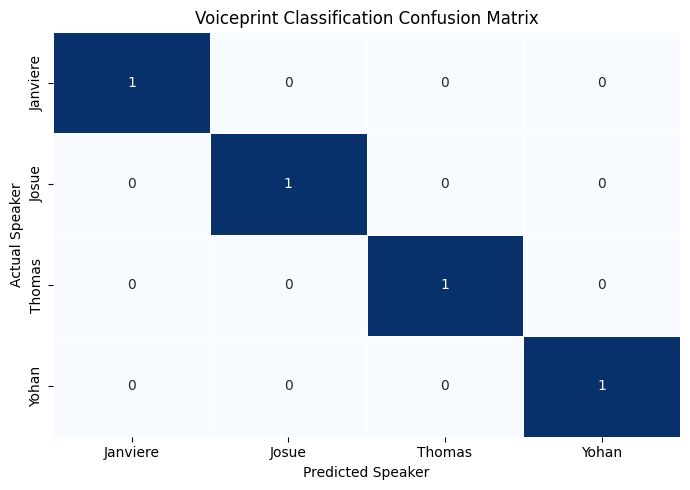

In [58]:
# 1. Generate predictions again
y_pred = voiceprint_model.predict(X_test)

# 2. Recreate the confusion matrix
from sklearn.metrics import confusion_matrix
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=voiceprint_model.classes_
)

# 3. Convert into a labelled DataFrame
cm_df = pd.DataFrame(
    cm,
    index=voiceprint_model.classes_,
    columns=voiceprint_model.classes_
)

# 4. Display confusion matrix
print("Confusion Matrix:")
display(cm_df)

# 5. Visualise
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_df,
    annot=True,
    fmt='d',
    cmap='Blues',
    linewidths=0.5,
    cbar=False
)

plt.title('Voiceprint Classification Confusion Matrix')
plt.xlabel('Predicted Speaker')
plt.ylabel('Actual Speaker')

plt.tight_layout()
plt.show()

### 6.6 Saving the Voiceprint Model and Evaluation Results

After training and evaluating the voiceprint classification model, the trained pipeline and its evaluation outputs were saved to Google Drive.

The saved model includes both the StandardScaler preprocessing step and the Logistic Regression classifier. This allows the complete pipeline to be loaded and reused without repeating the training process.

The confusion matrix, evaluation metrics, classification report, and speaker verification simulation results were also exported for documentation, reproducibility, and future reference.

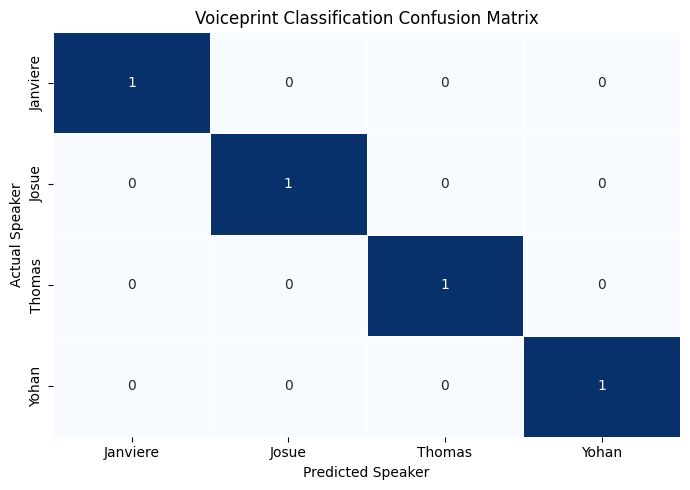


VOICEPRINT OUTPUTS SAVED SUCCESSFULLY
-------------------------------------
voiceprint_model.pkl
voiceprint_evaluation_metrics.csv
classification_report.csv
confusion_matrix.csv
confusion_matrix.png
verification_simulation.csv

Saving directory: /content/drive/MyDrive/ML- pipeline_Formative-2/outputs/audio output/voiceprint_outputs


In [59]:
import os
import joblib
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    log_loss,
    classification_report,
    confusion_matrix
)

# 1. Define the saving directory
SAVE_PATH = os.path.join(OUTPUT_ROOT, 'audio output', 'voiceprint_outputs')

os.makedirs(SAVE_PATH, exist_ok=True)

# 2. Generate predictions and probabilities
y_pred = voiceprint_model.predict(X_test)
y_prob = voiceprint_model.predict_proba(X_test)

# 3. Save trained model
model_path = os.path.join(SAVE_PATH, 'voiceprint_model.pkl')
joblib.dump(voiceprint_model, model_path)

# 4. Calculate evaluation metrics
metrics = {
    'Accuracy': accuracy_score(y_test, y_pred),
    'Precision': precision_score(y_test, y_pred, average='macro', zero_division=0),
    'Recall': recall_score(y_test, y_pred, average='macro', zero_division=0),
    'F1_Score': f1_score(y_test, y_pred, average='macro', zero_division=0),
    'Log_Loss': log_loss(y_test, y_prob, labels=voiceprint_model.classes_)
}

metrics_df = pd.DataFrame([metrics])

metrics_df.to_csv(
    os.path.join(SAVE_PATH, 'voiceprint_evaluation_metrics.csv'),
    index=False
)

# 5. Save classification report
report = classification_report(
    y_test,
    y_pred,
    labels=voiceprint_model.classes_,
    output_dict=True,
    zero_division=0
)

pd.DataFrame(report).transpose().to_csv(
    os.path.join(SAVE_PATH, 'classification_report.csv')
)

# 6. Save confusion matrix
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=voiceprint_model.classes_
)

cm_df = pd.DataFrame(
    cm,
    index=voiceprint_model.classes_,
    columns=voiceprint_model.classes_
)

cm_df.to_csv(
    os.path.join(SAVE_PATH, 'confusion_matrix.csv')
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_df,
    annot=True,
    fmt='d',
    cmap='Blues',
    linewidths=0.5,
    cbar=False
)

plt.title('Voiceprint Classification Confusion Matrix')
plt.xlabel('Predicted Speaker')
plt.ylabel('Actual Speaker')
plt.tight_layout()

plt.savefig(
    os.path.join(SAVE_PATH, 'confusion_matrix.png'),
    dpi=300,
    bbox_inches='tight'
)

plt.show()
plt.close()

# 7. Save speaker verification simulation
verification_df.to_csv(
    os.path.join(SAVE_PATH, 'verification_simulation.csv'),
    index=False
)

# 8. Verify saved files
print("\nVOICEPRINT OUTPUTS SAVED SUCCESSFULLY")
print("-------------------------------------")

for filename in os.listdir(SAVE_PATH):
    print(filename)

print("\nSaving directory:", SAVE_PATH)